In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import Image, display

from data_analysis.config import load_config

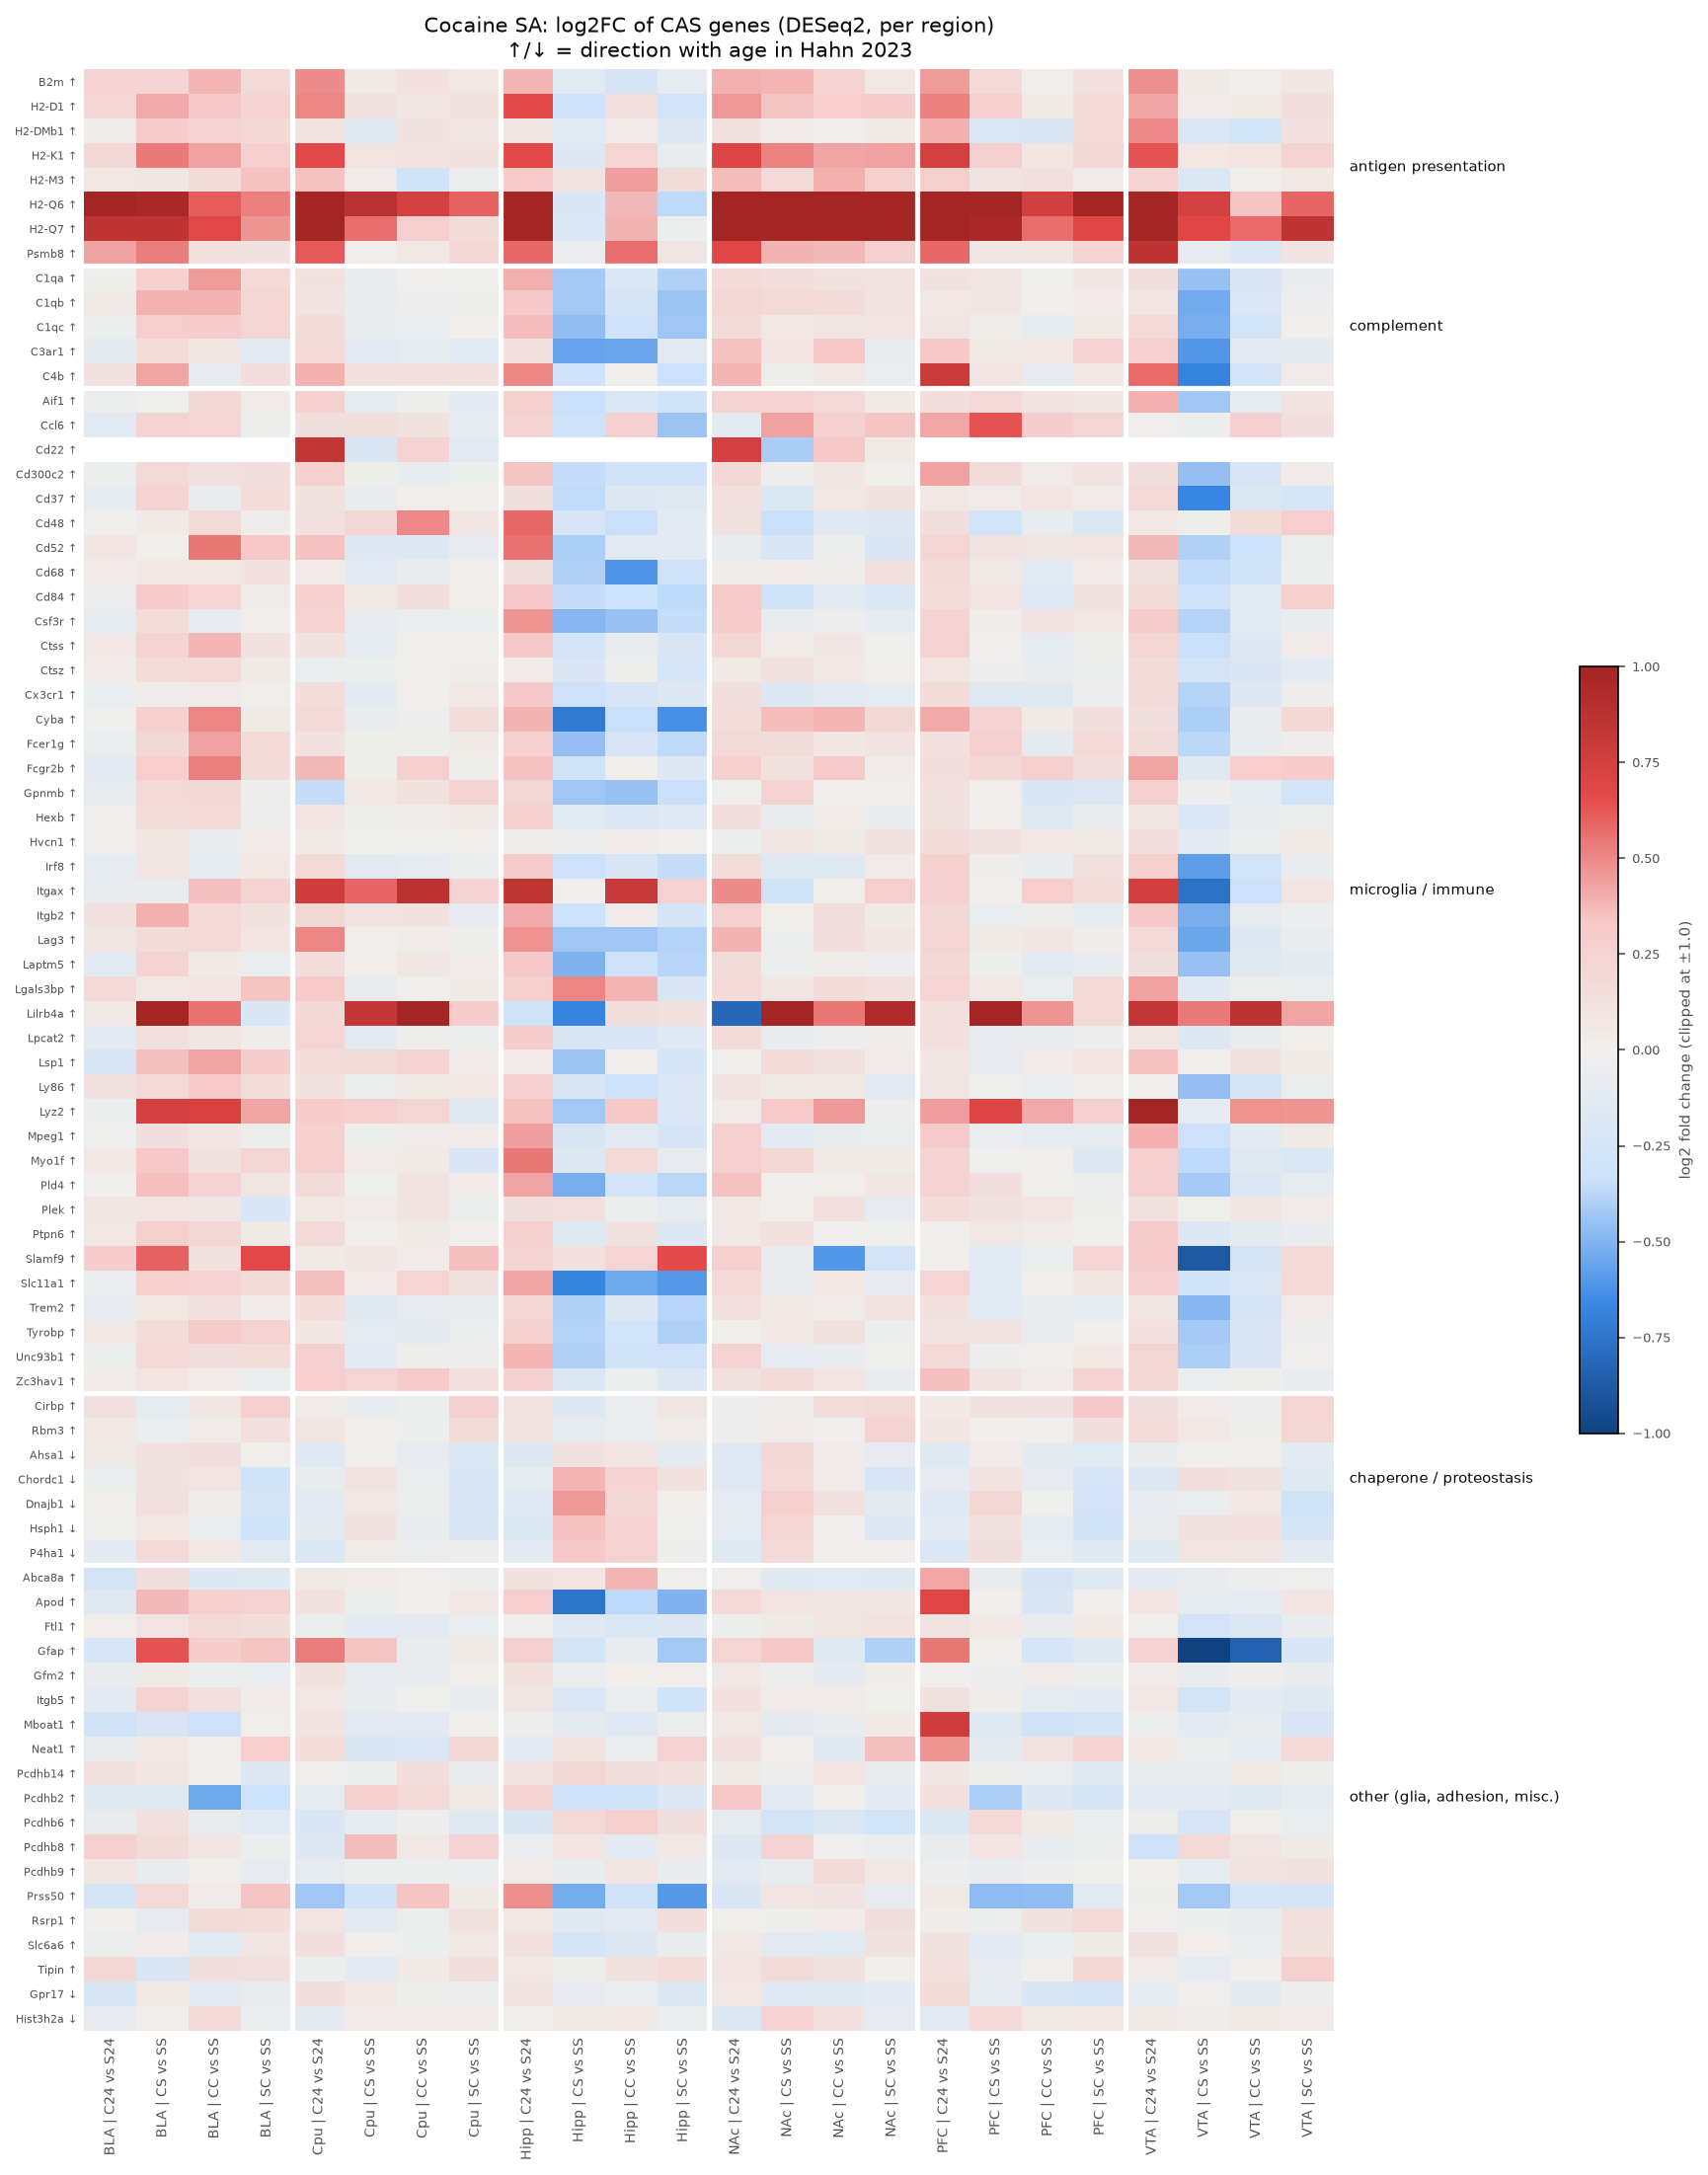

In [3]:
cfg = load_config()
tables, figs = cfg["paths"]["tables"], cfg["paths"]["figures"]
lfc = pd.read_csv(tables / "walker_cas_genes_log2fc.csv")
conc = pd.read_csv(tables / "table_walker_cas_concordance.csv")
display(Image(figs / "fig4_cas_genes_log2fc_heatmap.png"))

In [4]:
conc.query("gene_group == 'all CAS genes'").pivot(
    index="region", columns="comparison", values="frac_aging_like").round(2)

comparison,C24 vs S24,CC vs SS,CS vs SS,SC vs SS
region,,,,
BLA,0.47,0.78,0.80,0.78
Cpu,0.86,0.59,0.36,0.62
Hipp,0.91,0.32,0.13,0.23
NAc,0.81,0.66,0.57,0.65
PFC,0.95,0.48,0.57,0.63
VTA,0.87,0.22,0.15,0.57


In [5]:
conc.query("comparison == 'C24 vs S24' and gene_group != 'all CAS genes'").pivot(
    index="gene_group", columns="region", values="frac_aging_like").round(2)

region,BLA,Cpu,Hipp,NAc,PFC,VTA
gene_group,,,,,,
antigen presentation,1.00,1.00,1.00,1.00,1.00,1.00
chaperone / proteostasis,0.71,1.00,1.00,0.71,1.00,1.00
complement,0.40,1.00,1.00,1.00,1.00,1.00
microglia / immune,0.38,0.95,0.98,0.85,1.00,0.98
"other (glia, adhesion, misc.)",0.37,0.53,0.68,0.63,0.79,0.53


In [6]:
gene = "C4b"   # 아무 CAS 유전자로 바꿔 보세요
lfc.query("gene == @gene").pivot(index="region", columns="comparison", values="log2FoldChange").round(2)

comparison,C24 vs S24,CC vs SS,CS vs SS,SC vs SS
region,,,,
BLA,0.11,-0.08,0.43,0.14
Cpu,0.39,0.13,0.12,0.12
Hipp,0.51,-0.00,-0.31,-0.32
NAc,0.38,0.06,-0.02,-0.05
PFC,0.79,-0.08,0.09,0.06
VTA,0.57,-0.27,-0.69,0.04


Text(0.5, 1.0, 'CAS genes, C24 vs S24: up genes should sit above 0, down genes below')

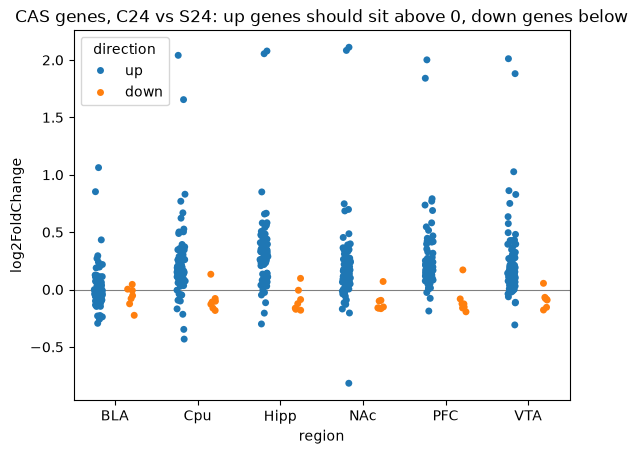

In [7]:
c24 = lfc.query("comparison == 'C24 vs S24'")
sns.stripplot(data=c24, x="region", y="log2FoldChange", hue="direction", dodge=True)
plt.axhline(0, color="gray", linewidth=0.8)
plt.title("CAS genes, C24 vs S24: up genes should sit above 0, down genes below")

In [8]:
deseq = pd.read_parquet(cfg["paths"]["processed"] / "deseq2" / "walker_deseq2.parquet")
deseq.query("region == 'Cpu' and comparison == 'C24 vs S24'").sort_values("padj").head(10)

,gene_id,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,region,comparison
83510,ENSMUSG00000079363,105.809371,2.090467,0.486860,4.293771,0.000018,0.153908,Cpu,C24 vs S24
78398,ENSMUSG00000039304,82.580117,0.906455,0.223519,4.055375,0.000050,0.153908,Cpu,C24 vs S24
81925,ENSMUSG00000060550,34.348773,2.040698,0.507916,4.017784,0.000059,0.153908,Cpu,C24 vs S24
83444,ENSMUSG00000078921,21.288942,2.072830,0.518548,3.997377,0.000064,0.153908,Cpu,C24 vs S24
75216,ENSMUSG00000030124,196.433499,0.502914,0.124882,4.027107,0.000056,0.153908,Cpu,C24 vs S24
81338,ENSMUSG00000055413,6.458101,2.229389,0.542257,4.111315,0.000039,0.153908,Cpu,C24 vs S24
83087,ENSMUSG00000074151,34.632209,1.466351,0.358117,4.094615,0.000042,0.153908,Cpu,C24 vs S24
69035,ENSMUSG00000001930,1019.994930,0.838093,0.212369,3.946392,0.000079,0.166817,Cpu,C24 vs S24
72987,ENSMUSG00000025366,206.695810,0.379061,0.100091,3.787175,0.000152,0.284779,Cpu,C24 vs S24
81247,ENSMUSG00000054708,526.504628,0.246191,0.066930,3.678335,0.000235,0.331239,Cpu,C24 vs S24


Text(0.5, 1.0, 'H2-Q7 per animal (6 regions each): animals differ more than regions')

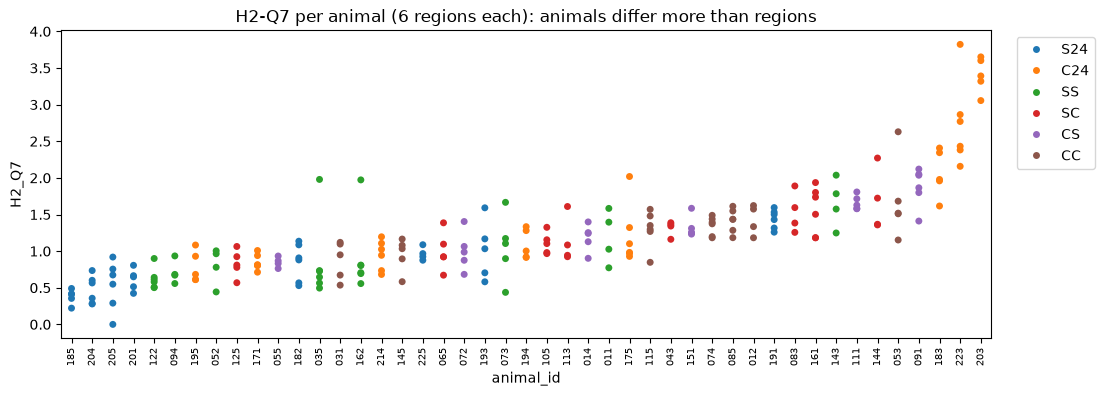

In [9]:
from data_analysis.loaders import load_processed
from data_analysis.normalize import log_cpm

walker = load_processed("walker", cfg)
mapping = pd.read_csv(tables / "cas_gene_mapping.csv").set_index("gene")
h2q7 = log_cpm(walker.counts).loc[mapping.loc["H2-Q7", "walker_id"]]

d = walker.meta.assign(H2_Q7=h2q7)
order = d.groupby("animal_id")["H2_Q7"].mean().sort_values().index
plt.figure(figsize=(12, 4))
sns.stripplot(data=d, x="animal_id", y="H2_Q7", hue="group", order=order, jitter=False)
plt.xticks(rotation=90, fontsize=7)
plt.legend(bbox_to_anchor=(1.02, 1))
plt.title("H2-Q7 per animal (6 regions each): animals differ more than regions")

In [10]:
from data_analysis.scoring import Signature, compute_cas, signature_for
from data_analysis.stats import hedges_g

sig = signature_for("walker", pd.read_csv(tables / "cas_gene_mapping.csv"))
mhc = {g for g in sig.symbol.values() if g.startswith("H2-")} | {"B2m", "Psmb8"}
drop = {i for i, g in sig.symbol.items() if g in mhc}
sig_no_mhc = Signature([g for g in sig.up if g not in drop], [g for g in sig.down if g not in drop], sig.symbol)

rows = []
for label, s in [("all 82", sig), ("minus MHC (8)", sig_no_mhc)]:
    scores, _ = compute_cas(walker, s, cfg["cas"])
    for region, x in scores.groupby("region", observed=True):
        rows.append({"signature": label, "region": region,
                     "g_C24_vs_S24": hedges_g(x.loc[x.group == "C24", "cas"], x.loc[x.group == "S24", "cas"])})
pd.DataFrame(rows).pivot(index="region", columns="signature", values="g_C24_vs_S24").round(2)

signature,all 82,minus MHC (8)
region,,
BLA,0.22,0.04
Cpu,1.04,0.98
Hipp,1.01,1.01
NAc,0.97,0.85
PFC,1.26,1.27
VTA,0.76,0.64
